# 12 — Weak-Constraint 4DVar with an Imperfect Model

Notebook [01](01_model_based_4dvar_L63.ipynb) assumed the model was perfect:
the observations could choose *which* Lorenz-63 trajectory, but never bend
it. Real models are wrong — missing physics, biased parameters,
discretisation error — and a strong-constraint analysis then has nowhere
to put the misfit except into the initial state. This notebook runs 4DVar
with a **deliberately biased** Lorenz-63 model and shows how admitting
model error as a control variable repairs the analysis.

## The generative model

Replace the perfect-model assumption $x_t = M(x_{t-1})$ by a noisy one:

$$
x_0 \sim \mathcal{N}(x_b, B), \qquad
x_t = M(x_{t-1}) + \eta_t, \quad \eta_t \sim \mathcal{N}(0, Q), \qquad
y_t = m_t \odot \big(H x_t + \varepsilon_t\big), \quad \varepsilon_t \sim \mathcal{N}(0, R).
$$

$M$ is now the *free* model — the one we have, not the one nature uses —
and $\eta_t$ is whatever is needed to make its one-step forecast land on
the true state. The control vector grows from $x_0$ to
$(x_0, \eta_1, \ldots, \eta_T)$, and the negative log posterior is

$$
J(x_0, \boldsymbol{\eta}) =
  \tfrac{1}{2}\|x_0 - x_b\|^2_{B^{-1}}
  + \tfrac{1}{2}\sum_{t=0}^{T} \|m_t \odot (y_t - H x_t)\|^2_{R^{-1}}
  + \tfrac{1}{2}\sum_{t=1}^{T} \|\eta_t\|^2_{Q^{-1}},
\qquad x_t = M(x_{t-1}) + \eta_t .
$$

Chapter [7](../07_weak_4dvar.md) derives this cost; the third term is the
only new ingredient, and $Q$ is the only new knob.

## Two parameterisations of the same problem

The map $(x_0, \boldsymbol{\eta}) \mapsto (x_0, x_1, \ldots, x_T)$ is a
triangular change of variables: $x_t$ depends on $\eta_t$ with unit
coefficient and on earlier increments only through $M$. Its Jacobian is
block lower-triangular with identity blocks on the diagonal, so its
determinant is one and the posterior density is *unchanged* by the
reparameterisation. Written in trajectory space, with
$\eta_t = x_t - M(x_{t-1})$ substituted back,

$$
J(x_{0:T}) =
  \tfrac{1}{2}\|x_0 - x_b\|^2_{B^{-1}}
  + \tfrac{1}{2}\sum_{t} \|m_t \odot (y_t - H x_t)\|^2_{R^{-1}}
  + \tfrac{1}{2}\sum_{t\ge 1} \|x_t - M(x_{t-1})\|^2_{Q^{-1}} .
$$

This is exactly the cost $U(x) = \alpha_{obs}\|m \odot (x - y)\|^2 +
\alpha_{prior}\|x - \varphi(x)\|^2$ that the learned-solver notebooks
([03](03_4dvarnet_L63.ipynb), [08](08_classical_4dvar_vs_4dvarnet_L63.ipynb))
minimise, with the reconstruction map $\varphi$ being the one-step ODE
flow $\varphi(x)_t = M(x_{t-1})$ instead of a neural autoencoder. In
vardax the two parameterisations are two objects:
[`WeakFourDVar`](xref:api#vardax.WeakFourDVar) minimises over $(x_0, \boldsymbol{\eta})$
with BFGS, and `DynIncrements.bind(ts)` turns the ODE into a `Prior` whose
residual is the third term above, so `variational_cost` minimises over
$x_{0:T}$ directly. Section 5 checks that they find the same analysis.

The two limits of $Q$ are worth holding in mind:

- $Q \to 0$ forces $\eta_t \to 0$ and recovers strong-constraint 4DVar:
  the dynamics become a hard constraint again.
- $Q \to \infty$ removes the dynamics entirely. Each observed time
  becomes an independent 3DVar problem, and the states at *unobserved*
  times are unconstrained — the minimiser leaves them wherever it
  started. Weak-constraint 4DVar interpolates between "trust the model"
  and "trust the data" with $Q$ as the dial.

## The linear-Gaussian reference point

When $M$ and $H$ are linear the posterior is Gaussian and its mean is the
fixed-interval (Rauch–Tung–Striebel) smoother: weak-constraint 4DVar and
the Kalman smoother are the same estimator computed by different
algorithms (Fisher, Leutbecher & Kelly 2005). The Kalman smoother
propagates covariances forward and backward; 4DVar minimises the joint
cost directly and never forms them. With nonlinear $M$ the smoother needs
linearisation while 4DVar needs an iterative minimiser — the variational
route is the one that stays exact.

## Identifiability of the increments

The increments are not all separately identifiable. Here observations
arrive every second step, so $\eta_{2k+1}$ and $\eta_{2k+2}$ are only
seen through the states from $x_{2k+2}$ onward that they jointly
produce. The $Q^{-1}$ penalty resolves the ambiguity as a minimum-norm
rule: the correction is split across the unobserved steps according to
how each propagates to the next observed state. Two consequences for
what we can expect to recover. The estimate $\eta^*$ need only match
$\eta^{\text{true}}$ in its *effect on the observed states*, not step
by step; and it will absorb whatever part of the observation noise it
can explain at a cost of $\|\eta\|^2_{Q^{-1}}$, so when $q$ is
comparable to $\sigma_{obs}$ the recovered increments carry a noisy
component that has nothing to do with the model.

In [1]:
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import optimistix as optx

from vardax import (
    Batch1D,
    DynIncrements,
    DynTrajectory,
    Lorenz63,
    MaskedIdentity,
    StrongFourDVar,
    WeakFourDVar,
    simulate_lorenz63,
    variational_cost,
)

## 1. A truth and a biased model

The truth is Lorenz-63 with the standard parameters. The assimilating
model uses $\rho = 26$ instead of $28$: the same equations, the same
attractor shape, but a systematically wrong Rayleigh number. That is the
most common kind of model error in practice — the right physics with the
wrong coefficient — and unlike additive noise it is *correlated with the
state*, so it cannot be averaged away.

The window is $T = 40$ steps at $\Delta t = 0.05$, i.e. two time units,
about twice the Lyapunov time. In notebook 01 that would already be long
for strong-constraint 4DVar; with a biased model it is hopeless, as the
free runs below show.

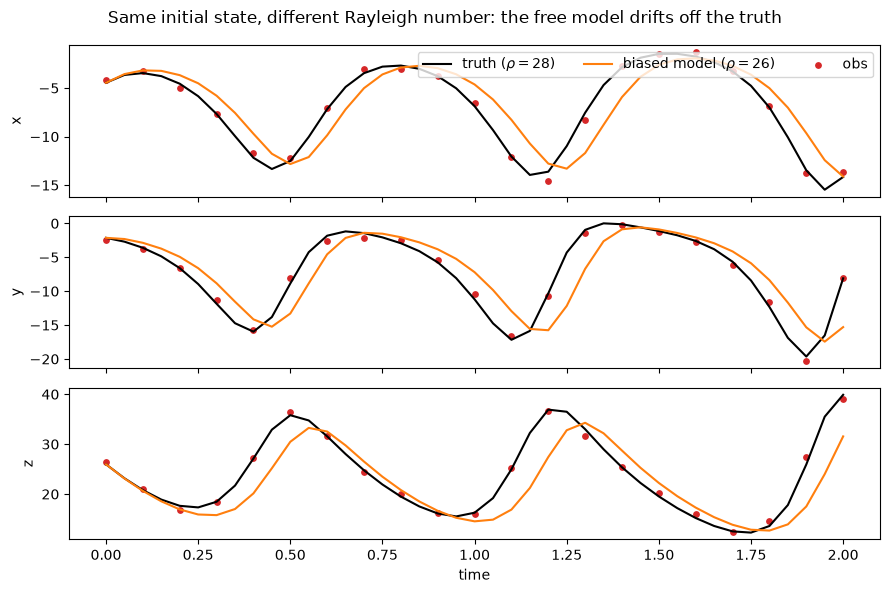

In [2]:
DT, T = 0.05, 40
SIGMA_OBS, SIGMA_BG = 0.5, 2.0
RHO_TRUE, RHO_MODEL = 28.0, 26.0
ts = jnp.arange(T + 1) * DT

truth_ode = DynTrajectory(model=Lorenz63(sigma=10.0, rho=RHO_TRUE, beta=8.0 / 3.0))
model_ode = DynTrajectory(model=Lorenz63(sigma=10.0, rho=RHO_MODEL, beta=8.0 / 3.0))
forward = model_ode.as_forward_model(dt=DT)  # the free model M

# Spin the truth onto its attractor, then take one window.
_, x_spin = simulate_lorenz63(jax.random.PRNGKey(0), rho=RHO_TRUE, dt=0.01, n_steps=500, n_burn_in=1000)
x_true = truth_ode(x_spin[-1], ts)  # (T+1, 3)

k_obs, k_bg = jax.random.split(jax.random.PRNGKey(1))
mask = jnp.zeros((T + 1, 3)).at[::2, :].set(1.0)
y_obs = x_true + SIGMA_OBS * jax.random.normal(k_obs, x_true.shape)
x_b = x_true[0] + SIGMA_BG * jax.random.normal(k_bg, (3,))
batch = Batch1D(input=(y_obs * mask)[None], mask=mask[None], target=x_true[None])

# Free runs of the true and biased models from the same initial state.
x_free_true = truth_ode(x_true[0], ts)
x_free_model = model_ode(x_true[0], ts)


def rmse(x):
    return jnp.sqrt(jnp.mean((x - x_true) ** 2, axis=-1))


fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(ts, x_true[:, i], color="black", label=r"truth ($\rho = 28$)")
    ax.plot(ts, x_free_model[:, i], color="tab:orange", label=r"biased model ($\rho = 26$)")
    ax.scatter(ts, jnp.where(mask[:, i] == 1, y_obs[:, i], jnp.nan), color="tab:red", s=15, label="obs")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right", ncol=3)
axes[-1].set_xlabel("time")
fig.suptitle("Same initial state, different Rayleigh number: the free model drifts off the truth")
plt.tight_layout()
plt.show()

## 2. The model error we are trying to estimate

Because we built the truth ourselves, we can compute the quantity weak
4DVar is supposed to recover: the one-step forecast error of the biased
model *along the true trajectory*,

$$
\eta^{\text{true}}_t = x^{\text{true}}_t - M\big(x^{\text{true}}_{t-1}\big), \qquad t = 1, \ldots, T .
$$

This is the increment that would make the free model exact. It is not a
fixed bias: it depends on where the state is on the attractor, and it is
largest in the $y$ component, where $\rho$ enters the equations.

per-component std of the true one-step model error: [0.08135663 0.35574192 0.17128477]
compare with the observation noise: 0.5


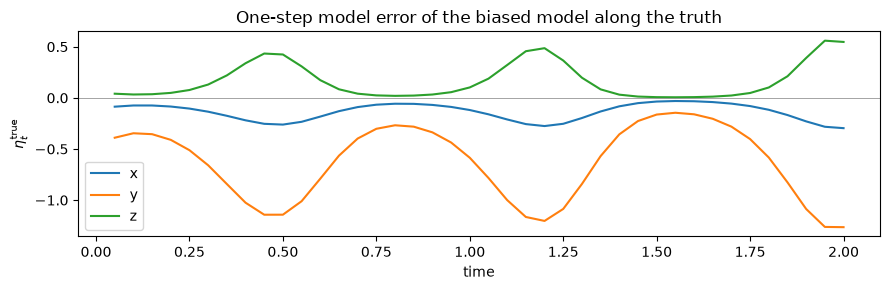

In [3]:
eta_true = x_true[1:] - jax.vmap(lambda x: forward.step(x, DT))(x_true[:-1])  # (T, 3)
print("per-component std of the true one-step model error:", jnp.std(eta_true, axis=0))
print(f"compare with the observation noise: {SIGMA_OBS}")

fig, ax = plt.subplots(figsize=(9, 3))
for i, name in enumerate(["x", "y", "z"]):
    ax.plot(ts[1:], eta_true[:, i], label=name)
ax.axhline(0.0, color="gray", lw=0.5)
ax.set_xlabel("time")
ax.set_ylabel(r"$\eta^{\rm true}_t$")
ax.set_title("One-step model error of the biased model along the truth")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Strong-constraint 4DVar with the wrong model

First the baseline: [`StrongFourDVar`](xref:api#vardax.StrongFourDVar) driven by the
biased forward, exactly as in notebook 01. The only freedom is $x_0$, so
the minimiser moves the initial state to wherever the biased trajectory
passes closest to the observations *on average* over the window. The
result fits nowhere well: the early states are distorted to buy a better
late fit, and the late fit is still poor because no $\rho = 26$
trajectory tracks a $\rho = 28$ one for two time units.

For reference we also run strong 4DVar with the *true* model. That is the
best any method can do here and sets the floor for the comparison.

In [4]:
def diag_cov(variance, n=3):
    op = lx.DiagonalLinearOperator(jnp.full(n, variance))
    return lx.TaggedLinearOperator(op, lx.positive_semidefinite_tag)


def make_strong(fwd):
    return StrongFourDVar(
        forward=fwd,
        obs_op=MaskedIdentity(),
        prior_mean=x_b,
        prior_cov_op=diag_cov(SIGMA_BG**2),
        obs_cov_op=diag_cov(SIGMA_OBS**2),
        max_steps=300,
    )


x0_strong_biased = make_strong(forward)(batch)[0]
x0_strong_true = make_strong(truth_ode.as_forward_model(dt=DT))(batch)[0]
traj_strong_biased = model_ode(x0_strong_biased, ts)
traj_strong_true = truth_ode(x0_strong_true, ts)
traj_background = model_ode(x_b, ts)

for name, traj in [
    ("background free run (biased model)", traj_background),
    ("strong 4DVar, biased model", traj_strong_biased),
    ("strong 4DVar, true model", traj_strong_true),
]:
    print(f"{name:38s} window RMSE = {float(jnp.sqrt(jnp.mean((traj - x_true) ** 2))):.3f}")

background free run (biased model)     window RMSE = 1.910
strong 4DVar, biased model             window RMSE = 1.241
strong 4DVar, true model               window RMSE = 0.163


## 4. Weak-constraint 4DVar

Now [`WeakFourDVar`](xref:api#vardax.WeakFourDVar) with the same biased forward and
$Q = q^2 I$. We take $q$ equal to the typical size of the true model
error (the standard deviation printed in section 2) — in practice one
would estimate it from innovation statistics or from comparing the free
model to a higher-resolution run, but the notebook's point is what the
extra control variable buys, not how to tune it, and section 5 sweeps it
anyway.

The analysis is a pair: the initial state $x_0^*$ and the increment
trajectory $\boldsymbol{\eta}^*$. The analysed states are recovered by
re-running the *biased* model and adding the increments at each step —
note that this is the same rollout the cost function used, so the fit
you see is the fit the minimiser saw.

q = 0.452
weak 4DVar, biased model              window RMSE = 0.427
initial-state error: background 1.621, strong 3.311, weak 0.596


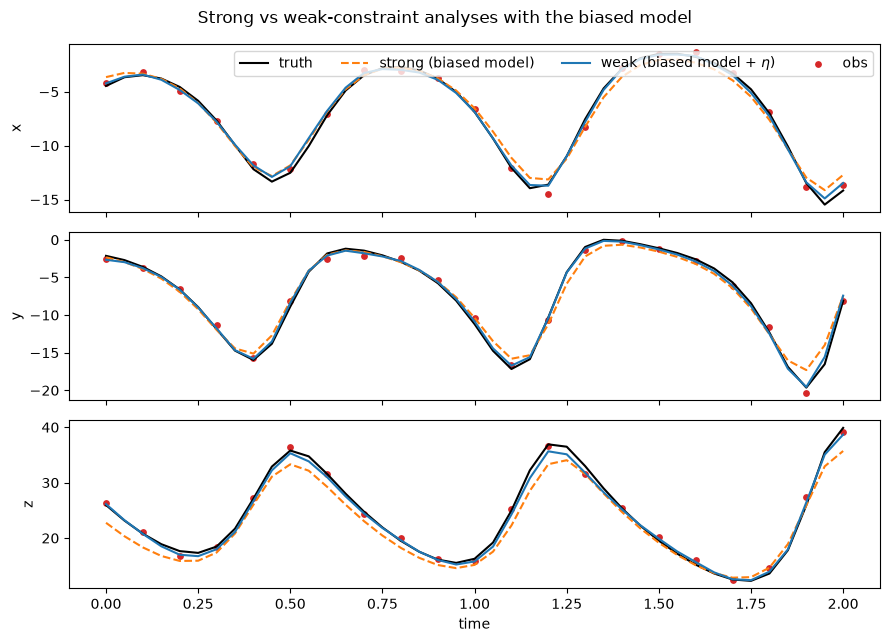

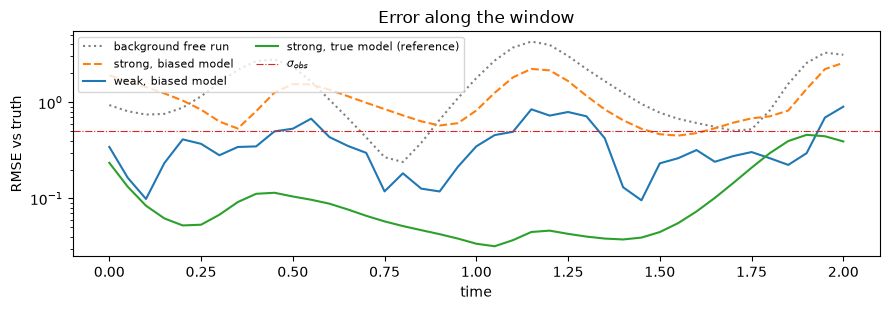

In [5]:
def rollout_with_increments(fwd, x0, etas):
    def step(x, eta_t):
        x_new = fwd.step(x, DT) + eta_t
        return x_new, x_new

    _, traj = jax.lax.scan(step, x0, etas)
    return jnp.concatenate([x0[None], traj], axis=0)


@jax.jit
def analyse_weak(q, batch):
    weak = WeakFourDVar(
        forward=forward,
        obs_op=MaskedIdentity(),
        prior_mean=x_b,
        prior_cov_op=diag_cov(SIGMA_BG**2),
        obs_cov_op=diag_cov(SIGMA_OBS**2),
        model_err_cov_op=diag_cov(q**2),
        minimiser=optx.BFGS(rtol=1e-6, atol=1e-6),
        max_steps=500,
    )
    x0_star, eta_star = weak(batch)
    return x0_star[0], eta_star[0]


Q_STD = float(jnp.sqrt(jnp.mean(eta_true**2)))
x0_weak, eta_weak = analyse_weak(Q_STD, batch)
traj_weak = rollout_with_increments(forward, x0_weak, eta_weak)

print(f"q = {Q_STD:.3f}")
print(f"weak 4DVar, biased model              window RMSE = {float(jnp.sqrt(jnp.mean((traj_weak - x_true) ** 2))):.3f}")
print(f"initial-state error: background {float(jnp.linalg.norm(x_b - x_true[0])):.3f}, "
      f"strong {float(jnp.linalg.norm(x0_strong_biased - x_true[0])):.3f}, "
      f"weak {float(jnp.linalg.norm(x0_weak - x_true[0])):.3f}")

fig, axes = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(ts, x_true[:, i], color="black", label="truth")
    ax.plot(ts, traj_strong_biased[:, i], color="tab:orange", linestyle="--", label="strong (biased model)")
    ax.plot(ts, traj_weak[:, i], color="tab:blue", label="weak (biased model + $\\eta$)")
    ax.scatter(ts, jnp.where(mask[:, i] == 1, y_obs[:, i], jnp.nan), color="tab:red", s=15, label="obs")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right", ncol=4)
axes[-1].set_xlabel("time")
fig.suptitle("Strong vs weak-constraint analyses with the biased model")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ts, rmse(traj_background), color="gray", linestyle=":", label="background free run")
ax.plot(ts, rmse(traj_strong_biased), color="tab:orange", linestyle="--", label="strong, biased model")
ax.plot(ts, rmse(traj_weak), color="tab:blue", label="weak, biased model")
ax.plot(ts, rmse(traj_strong_true), color="tab:green", label="strong, true model (reference)")
ax.axhline(SIGMA_OBS, color="tab:red", lw=0.8, linestyle="-.", label=r"$\sigma_{obs}$")
ax.set_yscale("log")
ax.set_xlabel("time")
ax.set_ylabel("RMSE vs truth")
ax.legend(ncol=2, fontsize=8)
ax.set_title("Error along the window")
plt.tight_layout()
plt.show()

Three things to read off the numbers and the error plot. The
strong-constraint analysis makes the *initial state worse than the
background*: the minimiser drags $x_0$ off the truth to buy a slightly
better average fit along a window the biased model cannot follow, which
is the failure mode chapter 7 calls climatological drift. The
weak-constraint error stays at or below the observation noise for most
of the window, at the price of a non-zero increment at every step. And
it sits between the strong-constraint error and the perfect-model
reference: the increments absorb most of the parameter error, but they
have to be inferred from noisy, gappy data, so some of it is left.

### Did we recover the model error?

Below, the recovered increments $\eta^*_t$ against the true one-step
error $\eta^{\text{true}}_t$ from section 2. In $y$, where the model
error is largest, the slow structure is recovered with the shrinkage a
Gaussian penalty on $\eta$ implies. In $x$ and $z$, where the true
error is no larger than what one observation-noise draw can induce in a
single step, the recovered increments are dominated by the noise-fitting
component anticipated in the introduction, and the correlation is weak.
The sawtooth between observed and unobserved steps is the minimum-norm
split at work. Weak-constraint 4DVar recovers the *effect* of model
error on the observed states; recovering the error itself, step by step,
needs either denser observations or a smaller $q$ than the true error
size — which trades the recovery for a worse fit.

correlation(eta*, eta_true) per component: ['0.02', '0.76', '0.40']
std ratio  (eta*  / eta_true) per component: ['1.60', '0.63', '1.39']


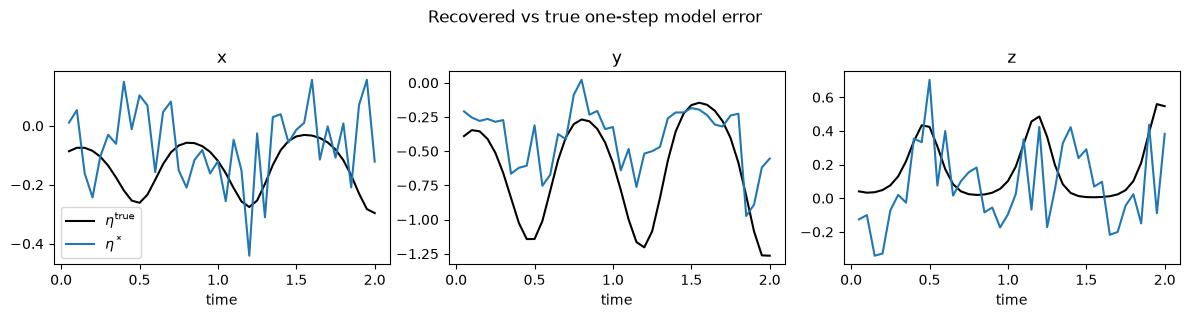

In [6]:
corr = [float(jnp.corrcoef(eta_weak[:, i], eta_true[:, i])[0, 1]) for i in range(3)]
print("correlation(eta*, eta_true) per component:", [f"{c:.2f}" for c in corr])
print("std ratio  (eta*  / eta_true) per component:",
      [f"{float(jnp.std(eta_weak[:, i]) / jnp.std(eta_true[:, i])):.2f}" for i in range(3)])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for i, (ax, name) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(ts[1:], eta_true[:, i], color="black", label=r"$\eta^{\rm true}$")
    ax.plot(ts[1:], eta_weak[:, i], color="tab:blue", label=r"$\eta^*$")
    ax.set_title(name)
    ax.set_xlabel("time")
axes[0].legend()
fig.suptitle("Recovered vs true one-step model error")
plt.tight_layout()
plt.show()

## 5. The model-error covariance is the dial

Chapter 7 calls $Q$ "the single most impactful tuning choice" in
weak-constraint 4DVar. The sweep below varies $q$ over three decades
with everything else fixed and records the window RMSE and the size of
the recovered increments.

- **Small $q$** reproduces the strong-constraint answer: the increments
  are penalised into zero and the biased model is imposed exactly.
- **Large $q$** lets the increments do anything the data ask for. The
  observed states are fitted, noise included, and the dynamics carry
  less and less information to the unobserved times. Here the curve
  flattens rather than climbing on that side: with every second step
  observed, one model step is a short leash and the unobserved states
  stay tied to their neighbours. With sparser observations the large-$q$
  side deteriorates faster. The right panel shows the other symptom: the
  size of the recovered increments saturates once $q$ exceeds the true
  error size, because from then on the data, not the prior, set them.
- The minimum sits near the actual size of the model error, which is
  what the Bayesian reading of $Q$ says it should be: $Q$ is the
  covariance of $\eta$, and the best analysis comes from telling the
  cost the truth about it.

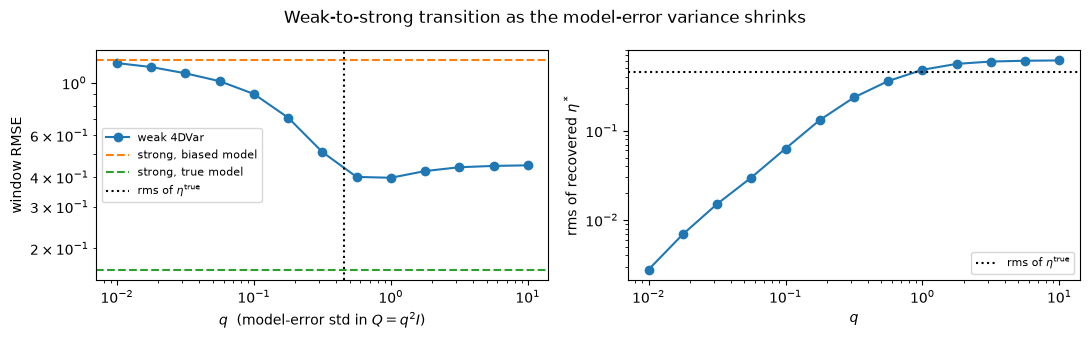

In [7]:
q_grid = jnp.logspace(-2.0, 1.0, 13)
sweep_rmse, sweep_eta = [], []
for q in q_grid:
    x0_q, eta_q = analyse_weak(q, batch)
    traj_q = rollout_with_increments(forward, x0_q, eta_q)
    sweep_rmse.append(float(jnp.sqrt(jnp.mean((traj_q - x_true) ** 2))))
    sweep_eta.append(float(jnp.sqrt(jnp.mean(eta_q**2))))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].loglog(q_grid, sweep_rmse, marker="o", color="tab:blue", label="weak 4DVar")
axes[0].axhline(float(jnp.sqrt(jnp.mean((traj_strong_biased - x_true) ** 2))), color="tab:orange", linestyle="--", label="strong, biased model")
axes[0].axhline(float(jnp.sqrt(jnp.mean((traj_strong_true - x_true) ** 2))), color="tab:green", linestyle="--", label="strong, true model")
axes[0].axvline(Q_STD, color="black", linestyle=":", label=r"rms of $\eta^{\rm true}$")
axes[0].set_xlabel(r"$q$  (model-error std in $Q = q^2 I$)")
axes[0].set_ylabel("window RMSE")
axes[0].legend(fontsize=8)
axes[1].loglog(q_grid, sweep_eta, marker="o", color="tab:blue")
axes[1].axhline(Q_STD, color="black", linestyle=":", label=r"rms of $\eta^{\rm true}$")
axes[1].set_xlabel(r"$q$")
axes[1].set_ylabel(r"rms of recovered $\eta^*$")
axes[1].legend(fontsize=8)
fig.suptitle("Weak-to-strong transition as the model-error variance shrinks")
plt.tight_layout()
plt.show()

## 6. The same cost in trajectory space

Finally the equivalence promised in the introduction. Bind the time grid
to a [`DynIncrements`](xref:api#vardax.DynIncrements) prior built from the
*biased* ODE; the resulting `Prior` maps a trajectory $x$ to
$\varphi(x) = (x_0, M(x_0), M(x_1), \ldots, M(x_{T-1}))$, so
$\|x - \varphi(x)\|^2 = \sum_{t \ge 1} \|x_t - M(x_{t-1})\|^2$ is the
increment penalty. `variational_cost` computes means rather than sums,
so to match $J$ exactly we scale by the element count and choose
$\alpha_{obs} = 1/(2\sigma_{obs}^2)$, $\alpha_{prior} = 1/(2 q^2)$
(the ratio $\alpha_{prior}/\alpha_{obs} = \sigma_{obs}^2 / q^2$ is what
matters for the minimiser; the absolute scale only matters for the
background term, which we add by hand since `variational_cost` has
none).

We minimise over the $(T+1) \times 3$ trajectory with the same BFGS,
starting from the biased free run from $x_b$ — which is precisely the
image of `WeakFourDVar`'s starting point $(x_b, \boldsymbol{0})$ under
the change of variables, so the two solvers start at the same point in
the same landscape and should end at the same minimum.

Which parameterisation to prefer is a conditioning question. In
increment space the observation term is dense (every $\eta_t$ affects
every later state through $M$), while in trajectory space the increment
term couples only neighbouring times and the Hessian is block
tridiagonal, like a discrete Laplacian along time — sparse, but with a
condition number that grows with the window length. The 4DVarNet
notebooks work in trajectory space because their $\varphi$ is a
spatial autoencoder with no natural increment parameterisation; here we
have both, and the choice is free.

cost at WeakFourDVar solution     : 51.9607
cost at trajectory-space solution : 51.9607
max |x difference| between the two analyses: 0.0011
max |eta difference|                        : 0.0004


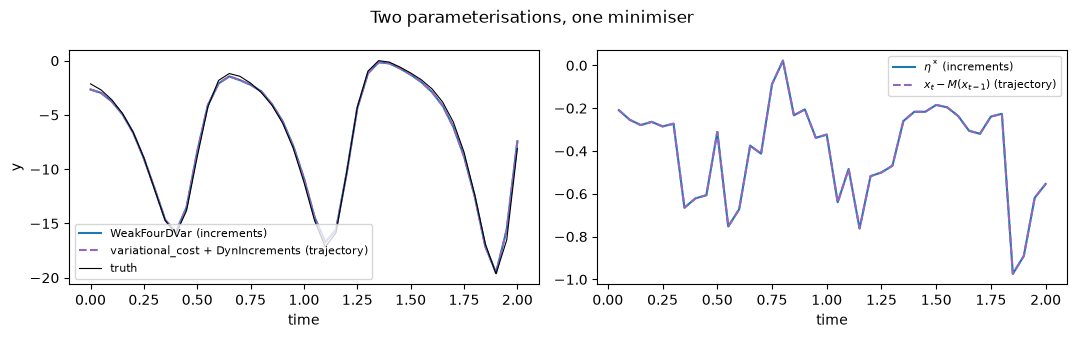

In [8]:
prior_fn = DynIncrements(model=Lorenz63(sigma=10.0, rho=RHO_MODEL, beta=8.0 / 3.0)).bind(ts)
n_elem = (T + 1) * 3


def cost_traj(x, args):
    q = args
    j_bg = 0.5 * jnp.sum((x[0] - x_b) ** 2) / SIGMA_BG**2
    u = variational_cost(
        x,
        Batch1D(input=batch.input[0], mask=batch.mask[0]),
        prior_fn,
        alpha_obs=1.0 / (2.0 * SIGMA_OBS**2),
        alpha_prior=1.0 / (2.0 * q**2),
    )
    return j_bg + n_elem * u


def cost_increments(x0, etas, q):
    x = rollout_with_increments(forward, x0, etas)
    return cost_traj(x, q)


sol = optx.minimise(
    cost_traj,
    optx.BFGS(rtol=1e-6, atol=1e-6),
    y0=traj_background,
    args=Q_STD,
    max_steps=2000,
    throw=False,
)
traj_from_traj_space = sol.value
eta_from_traj_space = traj_from_traj_space[1:] - jax.vmap(lambda x: forward.step(x, DT))(traj_from_traj_space[:-1])

print(f"cost at WeakFourDVar solution     : {float(cost_increments(x0_weak, eta_weak, Q_STD)):.4f}")
print(f"cost at trajectory-space solution : {float(cost_traj(traj_from_traj_space, Q_STD)):.4f}")
print(f"max |x difference| between the two analyses: {float(jnp.max(jnp.abs(traj_from_traj_space - traj_weak))):.4f}")
print(f"max |eta difference|                        : {float(jnp.max(jnp.abs(eta_from_traj_space - eta_weak))):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(ts, traj_weak[:, 1], color="tab:blue", label="WeakFourDVar (increments)")
axes[0].plot(ts, traj_from_traj_space[:, 1], color="tab:purple", linestyle="--", label="variational_cost + DynIncrements (trajectory)")
axes[0].plot(ts, x_true[:, 1], color="black", lw=0.8, label="truth")
axes[0].set_xlabel("time")
axes[0].set_ylabel("y")
axes[0].legend(fontsize=8)
axes[1].plot(ts[1:], eta_weak[:, 1], color="tab:blue", label=r"$\eta^*$ (increments)")
axes[1].plot(ts[1:], eta_from_traj_space[:, 1], color="tab:purple", linestyle="--", label=r"$x_t - M(x_{t-1})$ (trajectory)")
axes[1].set_xlabel("time")
axes[1].legend(fontsize=8)
fig.suptitle("Two parameterisations, one minimiser")
plt.tight_layout()
plt.show()

## Summary

- With a biased model, strong-constraint 4DVar has one lever, $x_0$, and
  pulls it in the wrong direction: it damages the early fit to reduce a
  late misfit it can never remove.
- Adding per-step increments $\eta_t$ with covariance $Q$ lets the
  analysis track the observations throughout the window; the recovered
  increments capture the model's actual one-step error where it is
  large, shrunk and contaminated by observation noise where it is not.
- $Q$ is the dial between strong-constraint ($Q \to 0$) and independent
  per-time analyses ($Q \to \infty$); the analysis is best when $Q$
  matches the real model-error variance.
- The increment and trajectory parameterisations describe the same
  posterior (unit-Jacobian change of variables). The trajectory form is
  `variational_cost` with an ODE prior in the role that a neural
  autoencoder plays in 4DVarNet; that is the bridge from this notebook
  to the learned solvers.

Chapter [20](../20_uncertainty.md) places additive model error among the
other sources of uncertainty; notebook [13](13_neural_closure_L96.ipynb)
attacks the same $\rho$-style structural error from the other side, by
*learning* the missing term in the model instead of estimating its
effect window by window.